## Data Cleaning on Car Registration Transactions in Malaysia (2023-2025)

### Fetching all three datasets from gov.my and appending

In [47]:
import pandas as pd
import fastparquet 

#Defining the data from gov.my URLs
urls = [
    "https://storage.data.gov.my/transportation/cars_2022.parquet",
    "https://storage.data.gov.my/transportation/cars_2023.parquet",
    "https://storage.data.gov.my/transportation/cars_2024.parquet",
    "https://storage.data.gov.my/transportation/cars_2025.parquet",
    "https://storage.data.gov.my/transportation/cars_2026.parquet",
] #take past 5 years. can take 2026 but need to compare the ratio

dataframes = [pd.read_parquet(url) for url in urls] #load parquet files as pd dataframes,using for loop to read each url 

cars = pd.concat(dataframes, ignore_index=True) #combining all three dataset, index is ignored to avoid repeating row numbers

print(f"Total rows and columns: {cars.shape}")
display(cars.head()) #displaying the first 5 rows of cars


Total rows and columns: (4019385, 7)


,date_reg,type,maker,model,colour,fuel,state
0,2022-01-01,window_van,Hyundai,Grand Starex,white,diesel,Rakan Niaga
1,2022-01-01,motokar,Mercedes Benz,A-Class,silver,petrol,Rakan Niaga
2,2022-01-01,motokar,Mercedes Benz,A-Class,white,petrol,Rakan Niaga
3,2022-01-01,jip,Mercedes Benz,GLB,grey,petrol,Rakan Niaga
4,2022-01-01,jip,Perodua,Aruz,white,petrol,Rakan Niaga


### Defining inspect_data function

In [49]:
#obtained from cici's

def inspect_data(df, name):
    print("=" * 60)
    print(name)
    print("=" * 60)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nDataset shape:")
    print(df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData information:")
    df.info()

    print("\nMissing values:")
    display(df.isnull().sum().to_frame("Missing Values"))

    print("\nDuplicate rows:")
    print(df.duplicated().sum())




In [50]:
inspect_data(cars, "CARS REGISTRATION IN MALAYSIA FOR THE PAST 5 YEARS")

CARS REGISTRATION IN MALAYSIA FOR THE PAST 5 YEARS

First 5 rows:


,date_reg,type,maker,model,colour,fuel,state
0,2022-01-01,window_van,Hyundai,Grand Starex,white,diesel,Rakan Niaga
1,2022-01-01,motokar,Mercedes Benz,A-Class,silver,petrol,Rakan Niaga
2,2022-01-01,motokar,Mercedes Benz,A-Class,white,petrol,Rakan Niaga
3,2022-01-01,jip,Mercedes Benz,GLB,grey,petrol,Rakan Niaga
4,2022-01-01,jip,Perodua,Aruz,white,petrol,Rakan Niaga



Dataset shape:
(4019385, 7)

Column names:
['date_reg', 'type', 'maker', 'model', 'colour', 'fuel', 'state']

Data information:
<class 'pandas.DataFrame'>
RangeIndex: 4019385 entries, 0 to 4019384
Data columns (total 7 columns):
 #   Column    Dtype         
---  ------    -----         
 0   date_reg  datetime64[us]
 1   type      object        
 2   maker     object        
 3   model     object        
 4   colour    object        
 5   fuel      object        
 6   state     object        
dtypes: datetime64[us](1), object(6)
memory usage: 214.7+ MB

Missing values:


,Missing Values
date_reg,0
type,0
maker,0
model,0
colour,0
fuel,0
state,0



Duplicate rows:
3268581


### Map the fuel types to three categories: ICE, HEV, EV and then extract year from date_reg

In [51]:
category_map = {
    'fuel': {
        'petrol': 'ICE',
        'diesel': 'ICE',
        'greendiesel': 'ICE',
        'ng': 'ICE',
        'lng': 'ICE',
        'petrol_ng': 'ICE',
        'greendiesel_ng': 'ICE',
        'diesel_ng': 'ICE',
        'hybrid_petrol': 'Hybrid',
        'hybrid_diesel': 'Hybrid',
        'electric': 'EV'
    }} #Hybrid = HEV + PHEV + MHEV


cars2 = cars.copy()
cars2['vehicle_category'] = cars2['fuel'].map(category_map['fuel']) #add new column that map fuel types to the three categories mapped above

cars2['year'] = cars2['date_reg'].dt.year

print(cars2.head()) 

    date_reg        type          maker         model  colour    fuel        state vehicle_category  year
0 2022-01-01  window_van        Hyundai  Grand Starex   white  diesel  Rakan Niaga              ICE  2022
1 2022-01-01     motokar  Mercedes Benz       A-Class  silver  petrol  Rakan Niaga              ICE  2022
2 2022-01-01     motokar  Mercedes Benz       A-Class   white  petrol  Rakan Niaga              ICE  2022
3 2022-01-01         jip  Mercedes Benz           GLB    grey  petrol  Rakan Niaga              ICE  2022
4 2022-01-01         jip        Perodua          Aruz   white  petrol  Rakan Niaga              ICE  2022


In [52]:
inspect_data(cars2, "CARS REGISTRATION IN MALAYSIA FOR THE PAST 5 YEARS")

CARS REGISTRATION IN MALAYSIA FOR THE PAST 5 YEARS

First 5 rows:


,date_reg,type,maker,model,colour,fuel,state,vehicle_category,year
0,2022-01-01,window_van,Hyundai,Grand Starex,white,diesel,Rakan Niaga,ICE,2022
1,2022-01-01,motokar,Mercedes Benz,A-Class,silver,petrol,Rakan Niaga,ICE,2022
2,2022-01-01,motokar,Mercedes Benz,A-Class,white,petrol,Rakan Niaga,ICE,2022
3,2022-01-01,jip,Mercedes Benz,GLB,grey,petrol,Rakan Niaga,ICE,2022
4,2022-01-01,jip,Perodua,Aruz,white,petrol,Rakan Niaga,ICE,2022



Dataset shape:
(4019385, 9)

Column names:
['date_reg', 'type', 'maker', 'model', 'colour', 'fuel', 'state', 'vehicle_category', 'year']

Data information:
<class 'pandas.DataFrame'>
RangeIndex: 4019385 entries, 0 to 4019384
Data columns (total 9 columns):
 #   Column            Dtype         
---  ------            -----         
 0   date_reg          datetime64[us]
 1   type              object        
 2   maker             object        
 3   model             object        
 4   colour            object        
 5   fuel              object        
 6   state             object        
 7   vehicle_category  str           
 8   year              int32         
dtypes: datetime64[us](1), int32(1), object(6), str(1)
memory usage: 260.7+ MB

Missing values:


,Missing Values
date_reg,0
type,0
maker,0
model,0
colour,0
fuel,0
state,0
vehicle_category,4
year,0



Duplicate rows:
3268581


### Resolving missing values in vehicle_category

In [53]:
cars2[cars2['vehicle_category'].isna()] #checking what entries that we can't map the category

,date_reg,type,maker,model,colour,fuel,state,vehicle_category,year
613230,2022-11-14,motokar,Honda,Fit,maroon,other,Rakan Niaga,NaN,2022
2845774,2025-07-14,window_van,Toyota,Alphard,white,other,Rakan Niaga,NaN,2025
2911149,2025-08-07,motokar,Honda,Civic,blue,other,Rakan Niaga,NaN,2025
3961433,2026-10-15,jip,ROX,Adamas,black,other,Selangor,NaN,2026


In [54]:
cars2[cars2['maker'].isin(['Toyota', 'Honda'])]
cars2[cars2['model'].isin(['Alphard', 'Civic'])] #checking other Toyota Alphard and Honda Civic fuel type 

,date_reg,type,maker,model,colour,fuel,state,vehicle_category,year
33,2022-01-02,window_van,Toyota,Alphard,white,petrol,Johor,ICE,2022
34,2022-01-02,window_van,Toyota,Alphard,white,petrol,Johor,ICE,2022
35,2022-01-02,window_van,Toyota,Alphard,white,petrol,Johor,ICE,2022
69,2022-01-03,motokar,Honda,Civic,blue,petrol,Kedah,ICE,2022
210,2022-01-03,window_van,Toyota,Alphard,white,petrol,W.P. Kuala Lumpur,ICE,2022
...,...,...,...,...,...,...,...,...,...
4019146,2026-10-31,window_van,Toyota,Alphard,white,petrol,W.P. Kuala Lumpur,ICE,2026
4019147,2026-10-31,window_van,Toyota,Alphard,white,petrol,Rakan Niaga,ICE,2026
4019148,2026-10-31,window_van,Toyota,Alphard,white,petrol,Rakan Niaga,ICE,2026
4019149,2026-10-31,window_van,Toyota,Alphard,black,petrol,Rakan Niaga,ICE,2026


In [55]:
cars2.loc[[2845774, 2911149], 'fuel'] = 'petrol' #since other Toyota Alphard & Honda Civic fuel type is petrol, we impute the data accordingly
cars2.loc[[3961433], 'fuel'] = 'electric'
cars2.loc[[613230], 'fuel'] = 'hybrid_petrol'

print(cars2.loc[[613230, 2845774, 2911149, 3961433]])

cars3 = cars2.copy()
cars3['vehicle_category'] = cars3['fuel'].map(category_map['fuel']) #remap fuel types to the three categories mapped previosuly
inspect_data(cars3, "CARS REGISTRATION IN MALAYSIA FOR THE PAST 5 YEARS")

          date_reg        type   maker    model  colour           fuel        state vehicle_category  year
613230  2022-11-14     motokar   Honda      Fit  maroon  hybrid_petrol  Rakan Niaga              NaN  2022
2845774 2025-07-14  window_van  Toyota  Alphard   white         petrol  Rakan Niaga              NaN  2025
2911149 2025-08-07     motokar   Honda    Civic    blue         petrol  Rakan Niaga              NaN  2025
3961433 2026-10-15         jip     ROX   Adamas   black       electric     Selangor              NaN  2026
CARS REGISTRATION IN MALAYSIA FOR THE PAST 5 YEARS

First 5 rows:


,date_reg,type,maker,model,colour,fuel,state,vehicle_category,year
0,2022-01-01,window_van,Hyundai,Grand Starex,white,diesel,Rakan Niaga,ICE,2022
1,2022-01-01,motokar,Mercedes Benz,A-Class,silver,petrol,Rakan Niaga,ICE,2022
2,2022-01-01,motokar,Mercedes Benz,A-Class,white,petrol,Rakan Niaga,ICE,2022
3,2022-01-01,jip,Mercedes Benz,GLB,grey,petrol,Rakan Niaga,ICE,2022
4,2022-01-01,jip,Perodua,Aruz,white,petrol,Rakan Niaga,ICE,2022



Dataset shape:
(4019385, 9)

Column names:
['date_reg', 'type', 'maker', 'model', 'colour', 'fuel', 'state', 'vehicle_category', 'year']

Data information:
<class 'pandas.DataFrame'>
RangeIndex: 4019385 entries, 0 to 4019384
Data columns (total 9 columns):
 #   Column            Dtype         
---  ------            -----         
 0   date_reg          datetime64[us]
 1   type              object        
 2   maker             object        
 3   model             object        
 4   colour            object        
 5   fuel              object        
 6   state             object        
 7   vehicle_category  str           
 8   year              int32         
dtypes: datetime64[us](1), int32(1), object(6), str(1)
memory usage: 260.7+ MB

Missing values:


,Missing Values
date_reg,0
type,0
maker,0
model,0
colour,0
fuel,0
state,0
vehicle_category,0
year,0



Duplicate rows:
3268583


Types of fuel in the data:
petrol = petrol
diesel = diesel
green diesel = greendiesel
natural gas = ng
liquified natural gas = lng
hydrogen = hydrogen
electricity - electric
hybrid = hybrid_petrol & hybrid_diesel
engine can use more than one type of fuel = petrol_ng, greendiesel_ng, diesel_ng

## Exploratory Data Analysis

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 4019385 entries, 0 to 4019384
Data columns (total 9 columns):
 #   Column            Dtype         
---  ------            -----         
 0   date_reg          datetime64[us]
 1   type              object        
 2   maker             object        
 3   model             object        
 4   colour            object        
 5   fuel              object        
 6   state             object        
 7   vehicle_category  str           
 8   year              int32         
dtypes: datetime64[us](1), int32(1), object(6), str(1)
memory usage: 260.7+ MB

 Descriptive Statistics:


,date_reg,type,maker,model,colour,fuel,state,vehicle_category,year
count,4019385,4019385,4019385,4019385,4019385,4019385,4019385,4019385,4.019385e+06
unique,NaN,5,143,896,16,9,17,3,NaN
top,NaN,motokar,Perodua,Bezza,grey,petrol,Rakan Niaga,ICE,NaN
freq,NaN,2337544,1606380,441196,954175,3470584,3448702,3739712,NaN
mean,2024-07-07 12:07:36.883031,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.023995e+03
min,2022-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.022000e+03
25%,2023-05-12 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.023000e+03
50%,2024-07-17 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.024000e+03
75%,2025-09-24 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.025000e+03
max,2026-10-31 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.026000e+03


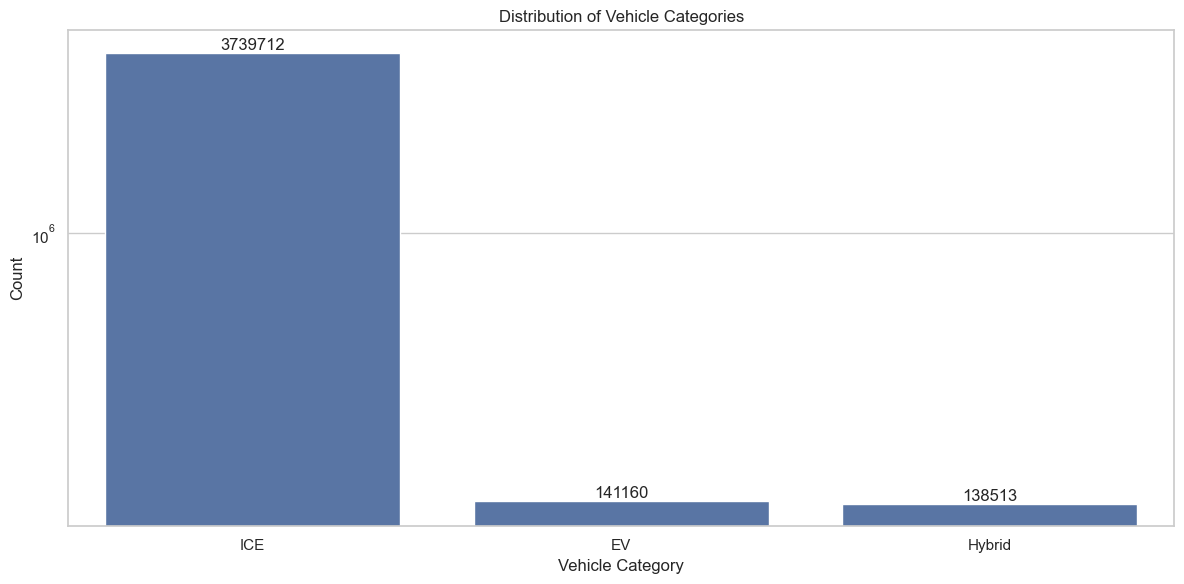

In [56]:
import matplotlib.pyplot as plt #for plotting
import seaborn as sns #create visualisations
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

sns.set_theme(style="whitegrid") #setting theme for sns plots

print("Data Types and Non-Null Counts:")
cars3.info() #call to display info about our cars dataframe

print("\n Descriptive Statistics:")
display(cars3.describe(include='all')) #calculate mean, median, min, max


plt.figure(figsize=(12, 6)) #canvas size, 12 inches wide, 6 inches tall
ax1 = sns.countplot(
    data=cars3,
    x='vehicle_category', #setting x-axis to vehicle_category column
    order=cars3['vehicle_category'].value_counts().index #order bars by frequency of vehicle categories
)
ax1.set_yscale('log') #set y-axis to log scale for better visibility of less frequent vehicle categories

ax1.bar_label(ax1.containers[0], fmt='%.0f') #add counts on top of bars

plt.title('Distribution of Vehicle Categories') #for title
plt.xlabel('Vehicle Category') #for x-axis label
plt.ylabel('Count') #for y-axis label
plt.tight_layout() #make sure labels dont get cut off
plt.show()

### Creating graphs with percentage value

In [57]:
yearly_counts = cars3.groupby(['year','vehicle_category']).size().reset_index(name='count')
yearly_total = yearly_counts.groupby('year')['count'].transform('sum')
yearly_counts['percentage'] = (yearly_counts['count']/yearly_total) * 100
print(yearly_counts)
print(yearly_total)

    year vehicle_category   count  percentage
0   2022               EV    3128    0.420006
1   2022           Hybrid   15378    2.064848
2   2022              ICE  726246   97.515146
3   2023               EV   13301    1.598046
4   2023           Hybrid   22215    2.669017
5   2023              ICE  796813   95.732937
6   2024               EV   21788    2.544623
7   2024           Hybrid   24526    2.864394
8   2024              ICE  809923   94.590984
9   2025               EV   44813    5.149807
10  2025           Hybrid   31190    3.584283
11  2025              ICE  794185   91.265910
12  2026               EV   58130    8.120087
13  2026           Hybrid   45204    6.314475
14  2026              ICE  612545   85.565438
0     744752
1     744752
2     744752
3     832329
4     832329
5     832329
6     856237
7     856237
8     856237
9     870188
10    870188
11    870188
12    715879
13    715879
14    715879
Name: count, dtype: int64


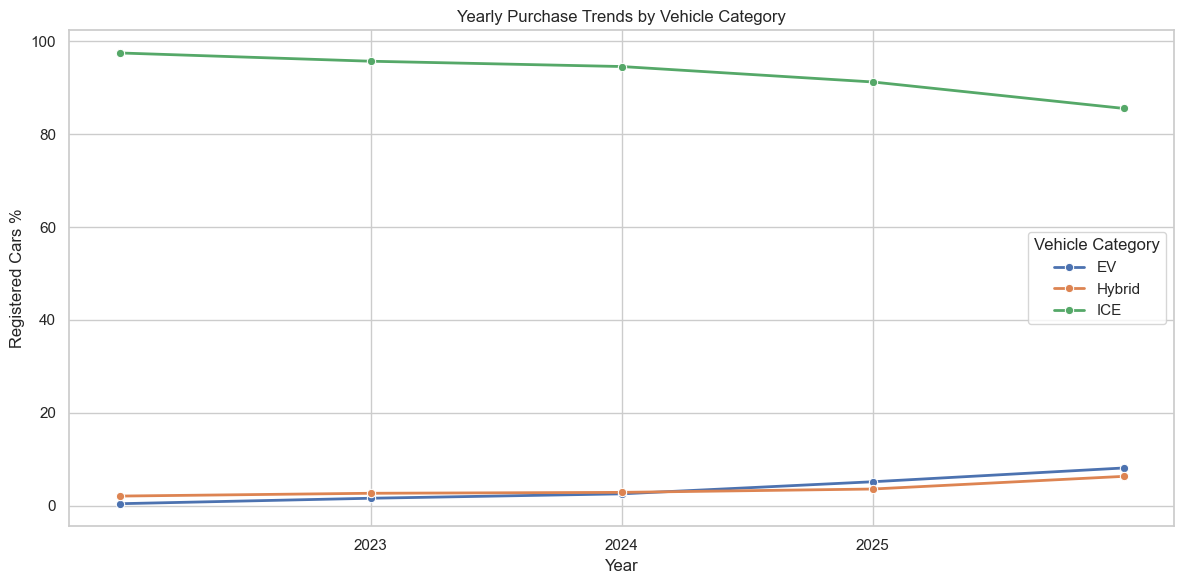

In [59]:
plt.figure(figsize=(12, 6)) # canvas size, 12 inches wide, 6 inches tall
ax2 = sns.lineplot(
     data=yearly_counts,
    x='year',  # x-axis for year
    y='percentage', # y-axis for yearly count
    hue='vehicle_category', # stack lines for ICE, HEV, and EV
    marker='o', # adds dots on each data point for clarity
    linewidth=2
)
    
#ax2.set_yscale('log') #to use log scale but I don't think it differs much from without using log scale hm

plt.title('Yearly Purchase Trends by Vehicle Category') # title for the graph
plt.xlabel('Year') # x-axis label
plt.ylabel('Registered Cars %') # y-axis label

plt.xticks([2023,2024,2025]) #because if not it will show as decimals.. idky

plt.legend(title='Vehicle Category')
plt.tight_layout() # so labels dont spill out
plt.show()

#if 2026, normalise using percentage

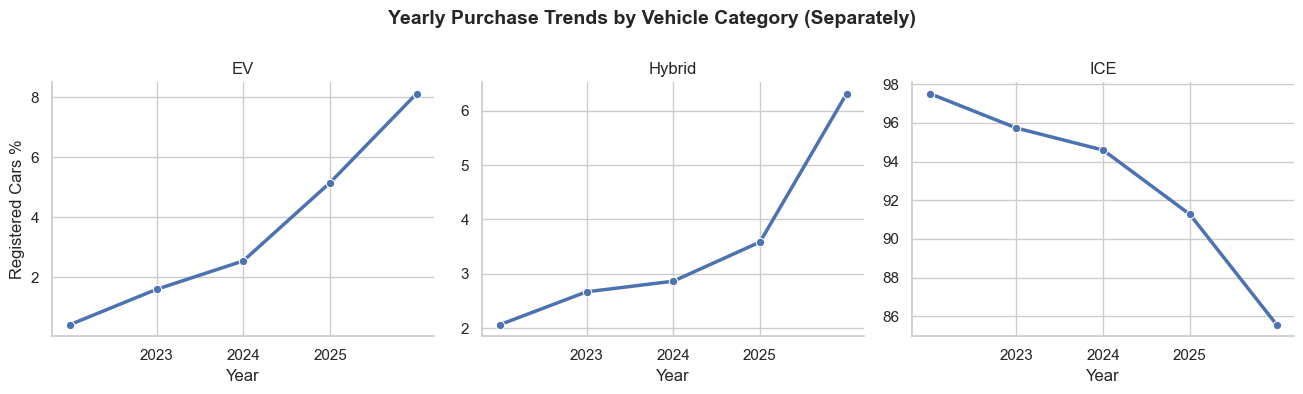

In [60]:
ax3 = sns.relplot( #relplot to show separately by creating multi-panel figure
    data=yearly_counts,
    x='year',
    y='percentage',
    col='vehicle_category',
    kind='line',
    marker='o',
    linewidth=2.5,
    height=4,
    aspect=1.1,
    facet_kws={'sharey': False} #sharey so that each graph use different scale
)

ax3.set_axis_labels("Year", "Registered Cars %") 
ax3.set_titles(col_template="{col_name}")
ax3.set(xticks=[2023, 2024, 2025])

ax3.fig.subplots_adjust(top=0.8)
ax3.fig.suptitle(('Yearly Purchase Trends by Vehicle Category (Separately)'), fontsize=14, fontweight='bold')

plt.show()

### Finding out top 10 models for each categories

In [61]:
cars3['maker-model'] = cars3['maker'].astype(str).str.title() + '-' + cars3['model'].astype(str).str.title() #add new column for maker-model combination, astype(str) to force str, str.title to caotalise

print("=== Top 10 Overall Across Three Categories ===:")
top_10_overall = cars3['maker-model'].value_counts().head(10)
print(top_10_overall)
print("\n" + "="*45 + "\n")

for vehicle_category in cars3['vehicle_category'].unique(): #use for loop to go through each unique category (3)
    print(f"=== Top 10 for {vehicle_category} ===:")
    top_10_category = cars3[cars3['vehicle_category'] == vehicle_category]['maker-model'].value_counts().head(10)
    print(top_10_category)
    print("\n" + "="*45 + "\n")

=== Top 10 Overall Across Three Categories ===:
maker-model
Perodua-Bezza    441196
Perodua-Axia     375305
Perodua-Myvi     338764
Proton-Saga      337605
Perodua-Alza     185396
Perodua-Ativa    164990
Honda-City       153503
Proton-X50       141242
Toyota-Hilux     128166
Toyota-Vios      125581
Name: count, dtype: int64


=== Top 10 for ICE ===:
maker-model
Perodua-Bezza    441196
Perodua-Axia     375305
Perodua-Myvi     338764
Proton-Saga      337605
Perodua-Alza     185396
Perodua-Ativa    164988
Honda-City       144439
Proton-X50       141242
Toyota-Hilux     128148
Toyota-Vios      120825
Name: count, dtype: int64


=== Top 10 for Hybrid ===:
maker-model
Toyota-Corolla Cross     33238
Honda-Hr-V               14247
Honda-City                9064
Mercedes Benz-C-Class     8509
Great Wall-Haval H6       8452
Proton-E.Mas 7            6957
Honda-Cr-V                6220
Mercedes Benz-Glc         5016
Toyota-Vios               4756
Toyota-Yaris Cross        3910
Name: count, dtype:

### Creating graphs (without percentage value)

In [62]:
vehicle_category_pct = (cars3['vehicle_category'].value_counts(normalize=True) * 100).reset_index()
vehicle_category_pct.columns = ['vehicle_category', 'percentage']

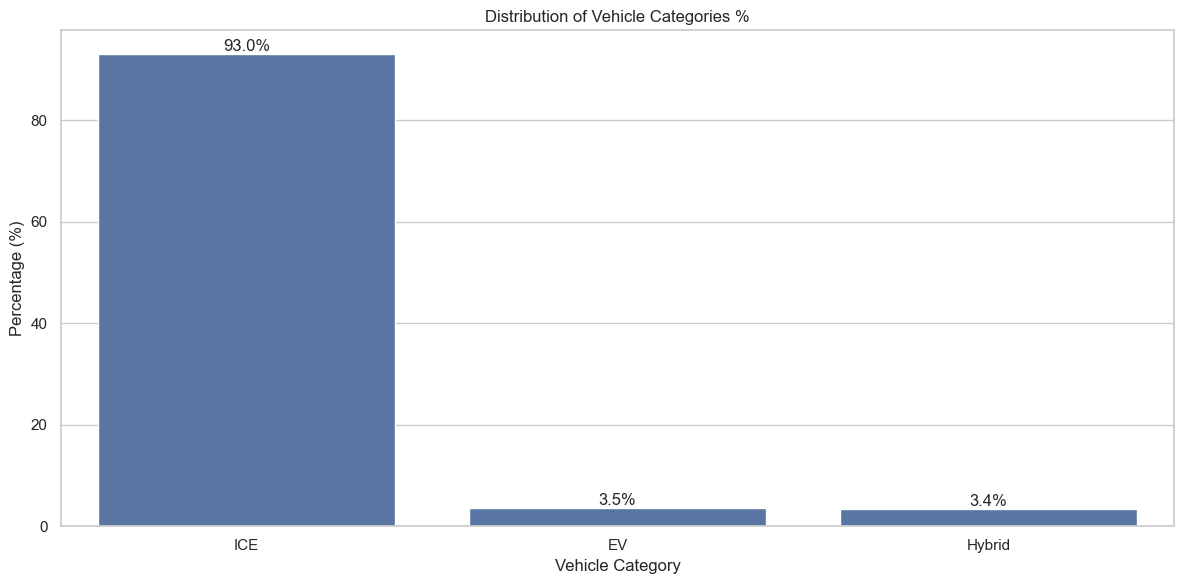

In [63]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6)) 

ax11 = sns.barplot(
    data=vehicle_category_pct,
    x='vehicle_category',
    y='percentage',   
    order=vehicle_category_pct['vehicle_category']
)

ax11.bar_label(ax11.containers[0], fmt='%.1f%%', label_type='edge') 

plt.title('Distribution of Vehicle Categories %')
plt.xlabel('Vehicle Category')
plt.ylabel('Percentage (%)')
plt.tight_layout()
plt.show()

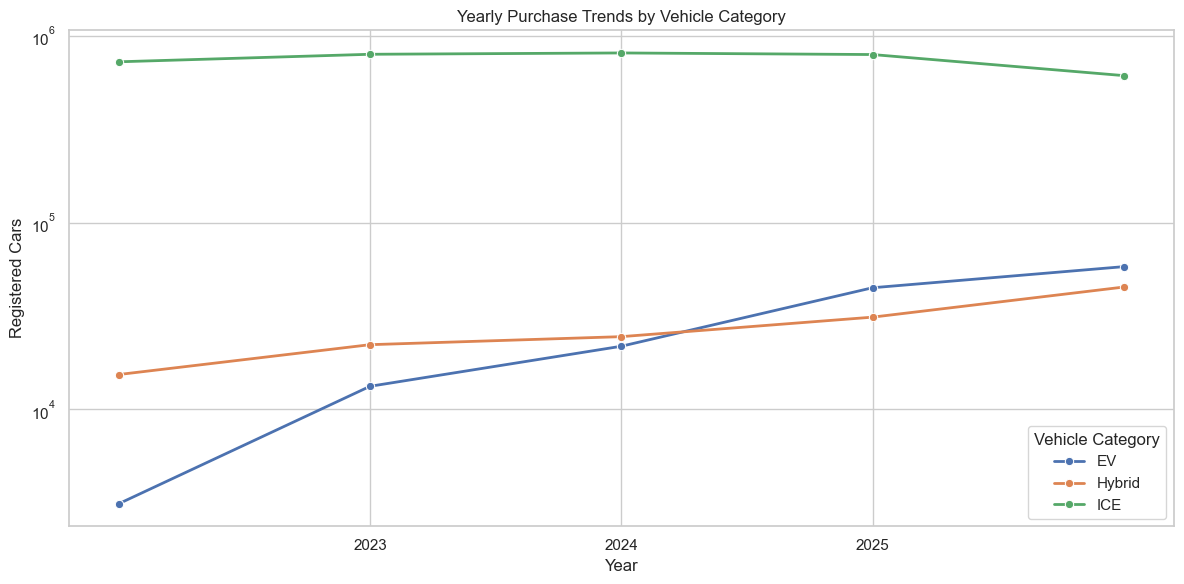

In [65]:
plt.figure(figsize=(12, 6)) # canvas size, 12 inches wide, 6 inches tall
ax21 = sns.lineplot(
     data=yearly_counts,
    x='year',  # x-axis for year
    y='count', # y-axis for yearly count
    hue='vehicle_category', # stack lines for ICE, HEV, and EV
    marker='o', # adds dots on each data point for clarity
    linewidth=2
)
    
ax21.set_yscale('log') #to use log scale

plt.title('Yearly Purchase Trends by Vehicle Category') # title for the graph
plt.xlabel('Year') # x-axis label
plt.ylabel('Registered Cars') # y-axis label

plt.xticks([2023,2024,2025]) #because if not it will show as decimals.. idky

plt.legend(title='Vehicle Category')
plt.tight_layout() # so labels dont spill out
plt.show()

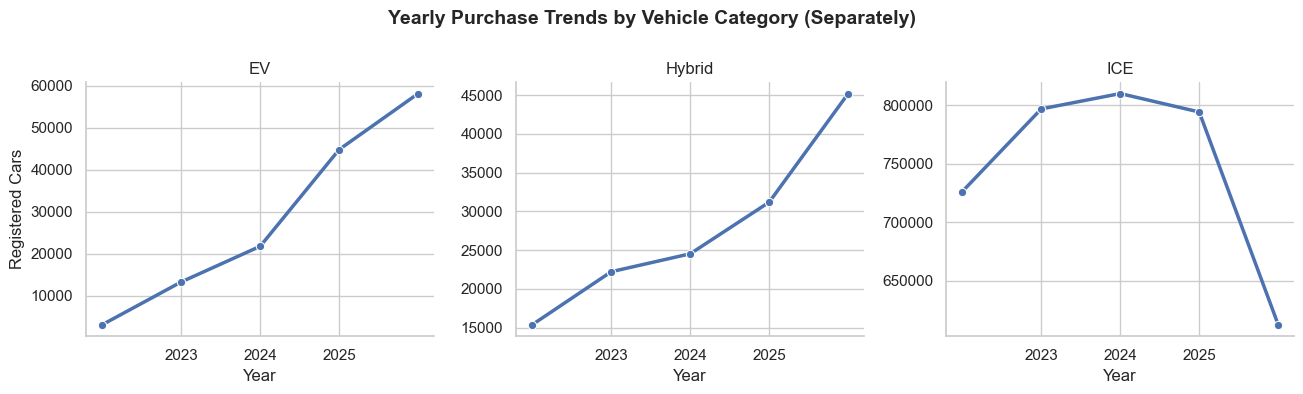

In [66]:
ax31 = sns.relplot( #relplot to show separately by creating multi-panel figure
    data=yearly_counts,
    x='year',
    y='count',
    col='vehicle_category',
    kind='line',
    marker='o',
    linewidth=2.5,
    height=4,
    aspect=1.1,
    facet_kws={'sharey': False} #sharey so that each graph use differnet scale
)

ax31.set_axis_labels("Year", "Registered Cars") 
ax31.set_titles(col_template="{col_name}")
ax31.set(xticks=[2023, 2024, 2025])

ax31.fig.subplots_adjust(top=0.8)
ax31.fig.suptitle(('Yearly Purchase Trends by Vehicle Category (Separately)'), fontsize=14, fontweight='bold')

plt.show()